<a href="https://colab.research.google.com/github/Ananyasaini06/Small-Object-Detection/blob/main/Small_Object_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import sys

print("Python version:", sys.version)
print("Environment is ready!")


Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Environment is ready!


In [2]:

import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))


PyTorch version: 2.11.0+cu130
GPU available: True
GPU name: Tesla T4


In [3]:

%pip install -q ultralytics sahi


In [4]:

import torch
import ultralytics
import sahi

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
print("Ultralytics:", ultralytics.__version__)
print("SAHI:", sahi.__version__)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
PyTorch: 2.11.0+cu130
GPU available: True
Ultralytics: 8.4.189
SAHI: 0.12.8


In [5]:

from ultralytics.data.utils import check_det_dataset

data = check_det_dataset("VisDrone.yaml")

print("Dataset path:", data["path"])
print("Training images:", data["train"])
print("Validation images:", data["val"])
print("Classes:", data["names"])



WARNING ⚠️ Dataset 'VisDrone.yaml' images not found, missing path '/content/datasets/VisDrone/images/val'
Unzipping /content/datasets/VisDrone/VisDrone2019-DET-val.zip to /content/datasets/VisDrone/VisDrone2019-DET-val...: 100% ━━━━━━━━━━━━ 1099/1099 213.4files/s 5.1s
Unzipping /content/datasets/VisDrone/VisDrone2019-DET-test-dev.zip to /content/datasets/VisDrone/VisDrone2019-DET-test-dev...: 100% ━━━━━━━━━━━━ 3223/3223 597.8files/s 5.4s
Unzipping /content/datasets/VisDrone/VisDrone2019-DET-train.zip to /content/datasets/VisDrone/VisDrone2019-DET-train...: 100% ━━━━━━━━━━━━ 12945/12945 1.7Kfiles/s 7.8s
Converting train: ━━━━━━━━━━━━ 6471 2.3Kit/s 3.0s
Converting val: ━━━━━━━━━━━━ 548 1.3Kit/s 0.3s
Converting test: ━━━━━━━━━━━━ 1610 2.2Kit/s 0.7s
Dataset download success ✅ (34.9s), saved to /content/datasets

Dataset path: /content/datasets/VisDrone
Training images: /content/datasets/VisDrone/images/train
Validation images: /content/datasets/VisDrone/images/val
Classes: {0: 'pedestrian

In [6]:

from pathlib import Path

root = Path("/content/datasets/VisDrone")

for split in ["train", "val", "test"]:
    images = root / "images" / split
    labels = root / "labels" / split

    print(f"\n{split.upper()}")
    print("Images folder exists:", images.exists())
    print("Image count:", len(list(images.glob("*"))) if images.exists() else 0)
    print("Labels folder exists:", labels.exists())
    print("Label count:", len(list(labels.glob("*.txt"))) if labels.exists() else 0)



TRAIN
Images folder exists: True
Image count: 6471
Labels folder exists: True
Label count: 6471

VAL
Images folder exists: True
Image count: 548
Labels folder exists: True
Label count: 548

TEST
Images folder exists: True
Image count: 1610
Labels folder exists: True
Label count: 1610


Image: 0000084_01436_d_0000004.jpg
Label file exists: True


array([[[  2,  49,  40],
        [  1,  48,  39],
        [  0,  45,  36],
        ...,
        [  8,  70,  56],
        [  7,  68,  54],
        [  4,  65,  51]],

       [[ 22,  67,  58],
        [ 11,  56,  47],
        [  0,  43,  34],
        ...,
        [ 15,  77,  63],
        [ 17,  78,  64],
        [ 16,  77,  63]],

       [[ 43,  86,  77],
        [ 34,  77,  68],
        [ 26,  69,  60],
        ...,
        [ 17,  77,  66],
        [ 23,  81,  70],
        [ 22,  80,  69]],

       ...,

       [[133,  90,  57],
        [134,  91,  58],
        [136,  93,  60],
        ...,
        [ 14,   0, 148],
        [ 14,   0, 148],
        [ 14,   0, 148]],

       [[134,  91,  58],
        [134,  91,  58],
        [136,  93,  60],
        ...,
        [ 14,   0, 148],
        [ 14,   0, 148],
        [ 14,   0, 148]],

       [[135,  92,  59],
        [135,  92,  59],
        [136,  93,  60],
        ...,
        [ 14,   0, 148],
        [ 14,   0, 148],
        [ 14,   0, 148]]], dtype=uint8)
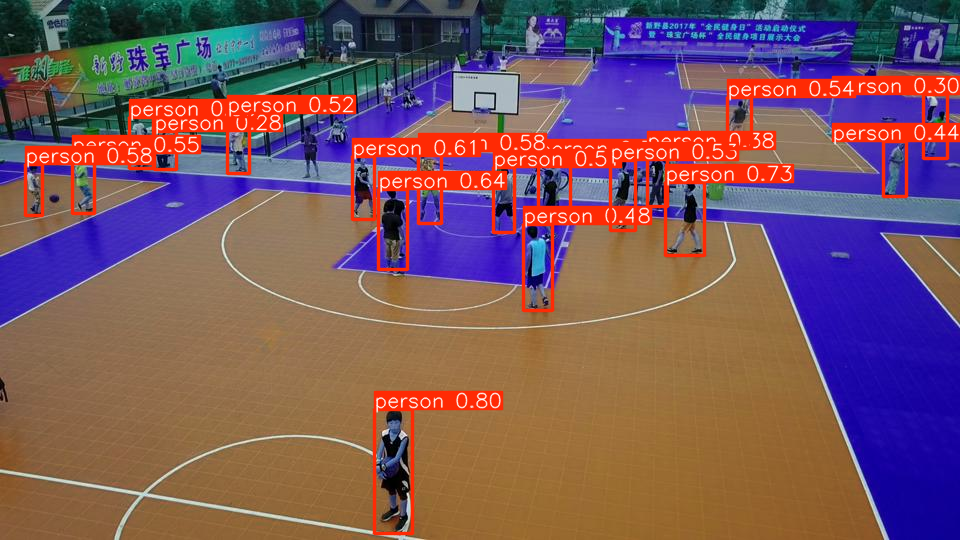

In [7]:

from ultralytics import YOLO
from pathlib import Path
import random

root = Path("/content/datasets/VisDrone")
image_files = list((root / "images/train").glob("*.jpg"))

image_path = random.choice(image_files)
label_path = root / "labels/train" / f"{image_path.stem}.txt"

print("Image:", image_path.name)
print("Label file exists:", label_path.exists())

model = YOLO("yolo11n.pt")
results = model.predict(
    source=str(image_path),
    imgsz=640,
    conf=0.25,
    verbose=False
)

display(results[0].plot())


It draws the bounding boxes from VisDrone's converted YOLO labels.

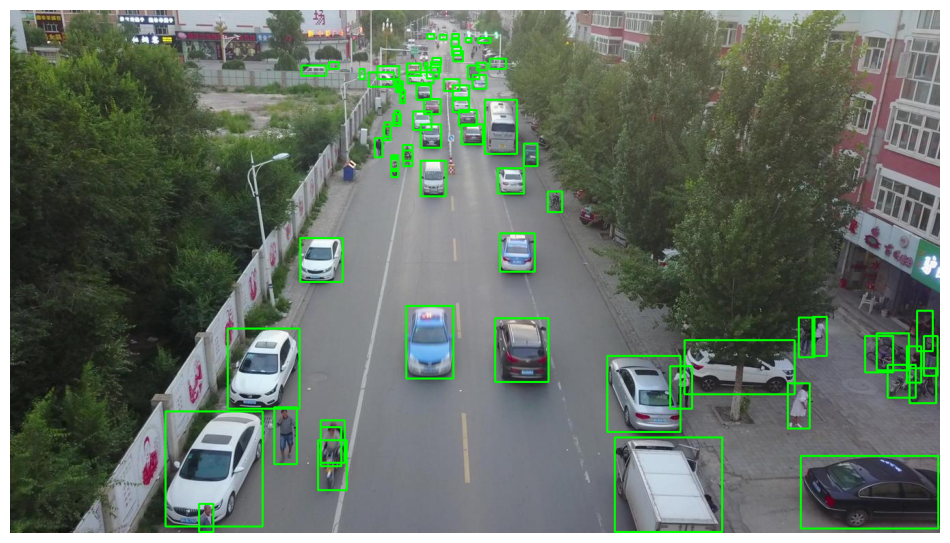

Image: 0000329_00601_d_0000768.jpg
Ground-truth objects: 78


In [8]:

import cv2
import matplotlib.pyplot as plt
from pathlib import Path
import random

root = Path("/content/datasets/VisDrone")
image_path = random.choice(list((root / "images/train").glob("*.jpg")))
label_path = root / "labels/train" / f"{image_path.stem}.txt"

image = cv2.imread(str(image_path))
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

h, w = image.shape[:2]

with open(label_path, "r") as f:
    for line in f:
        cls, xc, yc, bw, bh = map(float, line.split()[:5])

        x1 = int((xc - bw / 2) * w)
        y1 = int((yc - bh / 2) * h)
        x2 = int((xc + bw / 2) * w)
        y2 = int((yc + bh / 2) * h)

        cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)

plt.figure(figsize=(12, 8))
plt.imshow(image)
plt.axis("off")
plt.show()

print("Image:", image_path.name)
print("Ground-truth objects:", sum(
    1 for line in open(label_path) if line.strip()
))


Now we’ll fine-tune YOLO on VisDrone. First, we’ll run a short pilot to make sure training works before spending time on the full experiment.
We’ll use YOLO11n (the nano version), which is relatively lightweight and suitable for a first experiment.

In [9]:

from ultralytics import YOLO
import torch

print("GPU available:", torch.cuda.is_available())

model = YOLO("yolo11n.pt")

results = model.train(
    data="VisDrone.yaml",
    epochs=2,
    imgsz=640,
    batch=8,
    device=0,
    workers=2,
    project="/content/P10_runs",
    name="pilot",
    exist_ok=True
)


GPU available: True
Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=VisDrone.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=2, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=pilot, nbs=64, nms=None, opset=None, optimize=False, optim

Parameter	Meaning
yolo11n.pt	Loads pretrained model weights
data="VisDrone.yaml"	Uses your downloaded dataset
epochs=2	Trains for two passes through the dataset
imgsz=640	Resizes images for training
batch=8	Processes eight images per batch
device=0	Uses the first GPU
project	Saves experiment outputs

In [10]:

from pathlib import Path

weights = Path("/content/P10_runs/pilot/weights/best.pt")

print("Best model saved:", weights.exists())

if weights.exists():
    print("Model path:", weights)


Best model saved: True
Model path: /content/P10_runs/pilot/weights/best.pt


In [11]:

from ultralytics import YOLO

model = YOLO("/content/P10_runs/pilot/weights/best.pt")

metrics = model.val(
    data="VisDrone.yaml",
    split="val",
    imgsz=640,
    batch=8,
    device=0
)

print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)


Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,599,238 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1928.4±353.6 MB/s, size: 153.1 KB)
val: Scanning /content/datasets/VisDrone/labels/val.cache... 548 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 548/548 114.9Mit/s 0.0s
WARNING ⚠️ Dataset images contain up to 317 objects (val=317), but max_det=300. This mismatch can cap recall and produce invalid validation metrics. Raising it may increase validation cost but cannot increase model or export capacity, which may cap recall. Setting max_det=317 to match the observed maximum.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 69/69 6.6it/s 10.5s
                   all        548      38759      0.286      0.239      0.178     0.0959
            pedestrian        520       8844      0.205      0.345      0.202     


mAP50	Detection accuracy using an intersection-over-union threshold of 0.50
 mAP50-95	Average detection accuracy across IoU thresholds from 0.50 to 0.95

In [12]:

from pathlib import Path
import json

output_dir = Path("/content/P10_results")
output_dir.mkdir(parents=True, exist_ok=True)

results = {
    "training_epochs": 2,
    "image_size": 640,
    "mAP50": float(metrics.box.map50),
    "mAP50_95": float(metrics.box.map)
}

with open(output_dir / "pilot_metrics.json", "w") as f:
    json.dump(results, f, indent=4)

print("Saved to:", output_dir / "pilot_metrics.json")
print(results)


Saved to: /content/P10_results/pilot_metrics.json
{'training_epochs': 2, 'image_size': 640, 'mAP50': 0.17828681677555366, 'mAP50_95': 0.09588601036315092}


We’ll train for 15 epochs initially, using the same model and image size.This gives us a clean, reproducible 15-epoch training run rather than continuing from the two-epoch pilot. We'll keep the pilot as a separate experiment.

In [13]:

from ultralytics import YOLO
import torch

model = YOLO("yolo11n.pt")

results = model.train(
    data="VisDrone.yaml",
    epochs=15,
    imgsz=640,
    batch=8,
    device=0,
    workers=2,
    project="/content/P10_runs",
    name="final_baseline",
    exist_ok=True,
    patience=5,
    seed=42
)

print("Training complete!")
print("Best model: /content/P10_runs/final_baseline/weights/best.pt")


Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=VisDrone.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=final_baseline, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto,

Install and configure SAHI

In [14]:

%pip install -q sahi


load your trained model through SAHI: This uses your fine-tuned model, not a separate pretrained model.

In [16]:

from sahi import AutoDetectionModel

model_path = "/content/P10_runs/final_baseline/weights/best.pt"

detection_model = AutoDetectionModel.from_pretrained(
    model_type="ultralytics",
    model_path=model_path,
    confidence_threshold=0.25,
    device="cuda:0"
)

print("SAHI loaded the trained YOLO model successfully.")


SAHI loaded the trained YOLO model successfully.


Test tiled inference on one image This splits the image into overlapping 512 × 512 tiles, runs detection on each tile, and merges the results.

Important: This is only a smoke test. Detection count alone does not measure accuracy. Next, we'll evaluate tiled predictions against the validation ground truth and compare accuracy and latency fairly.

In [19]:

from sahi.predict import get_sliced_prediction
from pathlib import Path

image_path = next(
    Path("/content/datasets/VisDrone/images/val").glob("*.jpg")
)

result = get_sliced_prediction(
    str(image_path),
    detection_model,
    slice_height=512,
    slice_width=512,
    overlap_height_ratio=0.2,
    overlap_width_ratio=0.2
)

print("Image:", image_path.name)
print("Detections:", len(result.object_prediction_list))


Performing prediction on 8 slices.
Image: 0000271_02401_d_0000385.jpg
Detections: 82


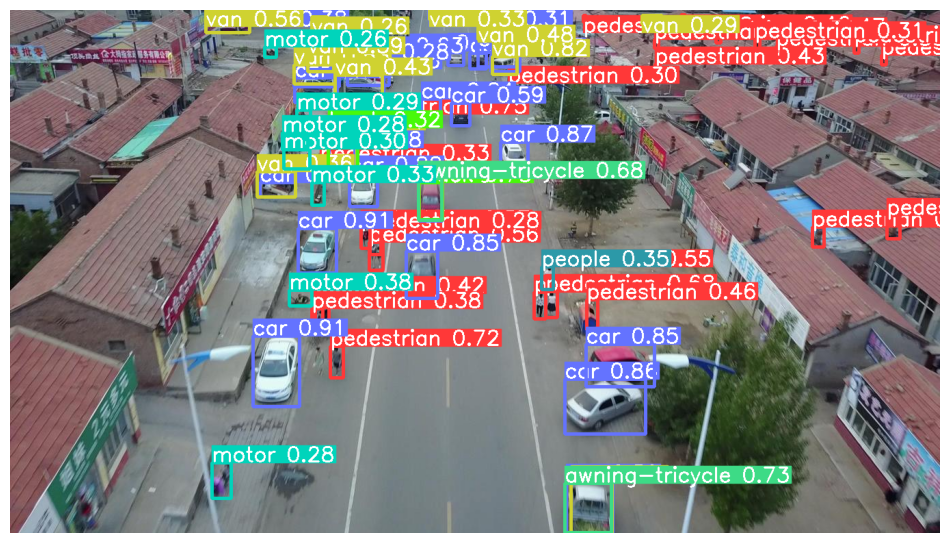

In [20]:

from IPython.display import display
from PIL import Image
import matplotlib.pyplot as plt

# Display image with SAHI detections
result.export_visuals(
    export_dir="/content/P10_results/sahi_visual"
)

img = Image.open(
    "/content/P10_results/sahi_visual/prediction_visual.png"
)

plt.figure(figsize=(12, 8))
plt.imshow(img)
plt.axis("off")
plt.show()


In [21]:

from IPython.display import display
from PIL import Image
import matplotlib.pyplot as plt
from pathlib import Path

visual_dir = Path("/content/P10_results/sahi_visual")
print("Saved files:", list(visual_dir.iterdir()))


Saved files: [PosixPath('/content/P10_results/sahi_visual/prediction_visual.png')]


Now we need to measure whether tiling actually improves detection accuracy, not just the number of detections.

In [22]:

from pathlib import Path
import time
import json
import numpy as np
from ultralytics import YOLO
from sahi import AutoDetectionModel
from sahi.predict import get_sliced_prediction

root = Path("/content/datasets/VisDrone")
image_paths = sorted((root / "images/val").glob("*.jpg"))[:100]

weights = "/content/P10_runs/final_baseline/weights/best.pt"

yolo = YOLO(weights)

sahi_model = AutoDetectionModel.from_pretrained(
    model_type="ultralytics",
    model_path=weights,
    confidence_threshold=0.25,
    device="cuda:0"
)

normal_times = []
tiled_times = []
normal_counts = []
tiled_counts = []

for image_path in image_paths:
    # Normal inference
    start = time.perf_counter()
    normal_result = yolo.predict(
        str(image_path), imgsz=640, conf=0.25, verbose=False
    )
    normal_times.append(time.perf_counter() - start)
    normal_counts.append(len(normal_result[0].boxes))

    # Tiled inference
    start = time.perf_counter()
    tiled_result = get_sliced_prediction(
        str(image_path),
        sahi_model,
        slice_height=512,
        slice_width=512,
        overlap_height_ratio=0.2,
        overlap_width_ratio=0.2,
        verbose=0
    )
    tiled_times.append(time.perf_counter() - start)
    tiled_counts.append(len(tiled_result.object_prediction_list))

summary = {
    "images_evaluated": len(image_paths),
    "normal_avg_latency_sec": float(np.mean(normal_times)),
    "tiled_avg_latency_sec": float(np.mean(tiled_times)),
    "normal_avg_detections": float(np.mean(normal_counts)),
    "tiled_avg_detections": float(np.mean(tiled_counts))
}

print(json.dumps(summary, indent=2))

with open("/content/P10_results/inference_comparison.json", "w") as f:
    json.dump(summary, f, indent=2)


{
  "images_evaluated": 100,
  "normal_avg_latency_sec": 0.017753577170033168,
  "tiled_avg_latency_sec": 0.14382474524997632,
  "normal_avg_detections": 30.81,
  "tiled_avg_detections": 52.88
}


Metric (100 images)	Normal YOLO	SAHI tiled
Average detections/image	30.81	52.88
Average latency/image	17.75 ms	143.82 ms
Relative detections	1.00×	1.72×
Relative latency	1.00×	8.10×

Tiling produced about 72% more detections, with approximately 8.1× the latency. More detections do not automatically mean better accuracy; some may be false positives.


Measurement	Purpose
Average latency	How long each method takes per image
Average detections	How many objects each method predicts
Accuracy	We will calculate this separately against ground-truth annotations



#Calculate actual small-object accuracy
We’ll calculate small-object AP@50 for normal YOLO and SAHI on the same 100 validation images.

For this experiment, we’ll define a small object as one whose bounding-box width and height are both at most 32 pixels. We’ll calculate class-wise average precision using an IoU threshold of 0.50, then average across classes with small ground-truth objects.


In [23]:

from pathlib import Path
from PIL import Image
from collections import defaultdict
from tqdm.auto import tqdm
import numpy as np
import json
import torch

from ultralytics import YOLO
from sahi import AutoDetectionModel
from sahi.predict import get_sliced_prediction

ROOT = Path("/content/datasets/VisDrone")
WEIGHTS = "/content/P10_runs/final_baseline/weights/best.pt"
RESULTS = Path("/content/P10_results")
RESULTS.mkdir(exist_ok=True)

image_paths = sorted((ROOT / "images/val").glob("*.jpg"))[:100]
model = YOLO(WEIGHTS)

sahi_model = AutoDetectionModel.from_pretrained(
    model_type="ultralytics",
    model_path=WEIGHTS,
    confidence_threshold=0.001,
    device="cuda:0"
)

# Store predictions and ground truth by method and class
preds = {
    "normal": defaultdict(list),
    "sahi": defaultdict(list)
}
ground_truth = defaultdict(dict)
class_names = model.names
small_limit = 32

def box_iou(a, b):
    x1 = max(a[0], b[0])
    y1 = max(a[1], b[1])
    x2 = min(a[2], b[2])
    y2 = min(a[3], b[3])

    inter = max(0, x2-x1) * max(0, y2-y1)
    area_a = max(0, a[2]-a[0]) * max(0, a[3]-a[1])
    area_b = max(0, b[2]-b[0]) * max(0, b[3]-b[1])
    return inter / max(area_a + area_b - inter, 1e-9)

for image_path in tqdm(image_paths, desc="Evaluating"):
    image_id = image_path.name
    label_path = ROOT / "labels/val" / f"{image_path.stem}.txt"

    with Image.open(image_path) as im:
        width, height = im.size

    gt_by_class = defaultdict(list)

    if label_path.exists():
        for line in label_path.read_text().splitlines():
            values = line.split()
            if len(values) < 5:
                continue

            cls, xc, yc, bw, bh = map(float, values[:5])
            box = [
                (xc - bw/2) * width,
                (yc - bh/2) * height,
                (xc + bw/2) * width,
                (yc + bh/2) * height
            ]

            if bw * width <= small_limit and bh * height <= small_limit:
                gt_by_class[int(cls)].append(box)

    for cls in class_names:
        ground_truth[cls][image_id] = gt_by_class[cls]

    # Normal YOLO: retain low-confidence predictions for AP calculation
    if torch.cuda.is_available():
        torch.cuda.synchronize()

    normal = model.predict(
        str(image_path), imgsz=640, conf=0.001,
        max_det=3000, device=0, verbose=False
    )[0]

    for box, score, cls in zip(
        normal.boxes.xyxy.cpu().numpy(),
        normal.boxes.conf.cpu().numpy(),
        normal.boxes.cls.cpu().numpy().astype(int)
    ):
        w, h = box[2]-box[0], box[3]-box[1]
        if w <= small_limit and h <= small_limit:
            preds["normal"][cls].append(
                (float(score), image_id, box.tolist())
            )

    # SAHI tiled inference
    sliced = get_sliced_prediction(
        str(image_path),
        sahi_model,
        slice_height=512,
        slice_width=512,
        overlap_height_ratio=0.2,
        overlap_width_ratio=0.2,
        postprocess_type="GREEDYNMM",
        verbose=0
    )

    for obj in sliced.object_prediction_list:
        box = obj.bbox.to_xyxy()
        w, h = box[2]-box[0], box[3]-box[1]
        cls = int(obj.category.id)

        if w <= small_limit and h <= small_limit:
            preds["sahi"][cls].append(
                (float(obj.score.value), image_id, box)
            )

def calculate_ap(method, cls):
    gt = ground_truth[cls]
    total_gt = sum(len(boxes) for boxes in gt.values())

    if total_gt == 0:
        return None

    detections = sorted(
        preds[method][cls], key=lambda x: x[0], reverse=True
    )

    matched = {img: set() for img in gt}
    tp, fp = [], []

    for score, img, box in detections:
        boxes = gt.get(img, [])
        best_iou, best_idx = 0, -1

        for idx, gt_box in enumerate(boxes):
            if idx in matched[img]:
                continue
            iou = box_iou(box, gt_box)
            if iou > best_iou:
                best_iou, best_idx = iou, idx

        if best_iou >= 0.50:
            matched[img].add(best_idx)
            tp.append(1)
            fp.append(0)
        else:
            tp.append(0)
            fp.append(1)

    if not tp:
        return 0.0

    tp = np.cumsum(tp)
    fp = np.cumsum(fp)
    recall = tp / total_gt
    precision = tp / np.maximum(tp + fp, 1e-12)

    # Interpolated average precision
    recall = np.concatenate(([0], recall, [1]))
    precision = np.concatenate(([0], precision, [0]))

    for i in range(len(precision)-2, -1, -1):
        precision[i] = max(precision[i], precision[i+1])

    changes = np.where(recall[1:] != recall[:-1])[0]
    return float(np.sum(
        (recall[changes+1] - recall[changes]) * precision[changes+1]
    ))

valid_classes = [
    cls for cls in class_names
    if sum(len(v) for v in ground_truth[cls].values()) > 0
]

summary = {}
for method in ["normal", "sahi"]:
    per_class = {
        class_names[cls]: calculate_ap(method, cls)
        for cls in valid_classes
    }
    summary[method] = {
        "small_object_AP50_percent": round(
            100 * np.mean(list(per_class.values())), 2
        ),
        "per_class_AP50_percent": {
            name: round(100 * value, 2)
            for name, value in per_class.items()
        }
    }

print(json.dumps(summary, indent=2))

with open(RESULTS / "small_object_ap50.json", "w") as f:
    json.dump(summary, f, indent=2)

print("Saved:", RESULTS / "small_object_ap50.json")


Evaluating:   0%|          | 0/100 [00:00<?, ?it/s]

2026-10-26 08:19:03,759 - sahi - WARNING - Switching postprocess type/metric to NMS/IOU since model confidence threshold is low (0.001). (predict.py:327)
2026-10-26 08:19:06,378 - sahi - WARNING - Switching postprocess type/metric to NMS/IOU since model confidence threshold is low (0.001). (predict.py:327)
2026-10-26 08:19:07,163 - sahi - WARNING - Switching postprocess type/metric to NMS/IOU since model confidence threshold is low (0.001). (predict.py:327)
2026-10-26 08:19:07,567 - sahi - WARNING - Switching postprocess type/metric to NMS/IOU since model confidence threshold is low (0.001). (predict.py:327)
2026-10-26 08:19:07,934 - sahi - WARNING - Switching postprocess type/metric to NMS/IOU since model confidence threshold is low (0.001). (predict.py:327)
2026-10-26 08:19:08,303 - sahi - WARNING - Switching postprocess type/metric to NMS/IOU since model confidence threshold is low (0.001). (predict.py:327)
2026-10-26 08:19:08,652 - sahi - WARNING - Switching postprocess type/metric

{
  "normal": {
    "small_object_AP50_percent": 16.13,
    "per_class_AP50_percent": {
      "pedestrian": 13.52,
      "people": 14.1,
      "bicycle": 2.7,
      "car": 50.66,
      "van": 5.75,
      "truck": 28.21,
      "tricycle": 18.52,
      "awning-tricycle": 7.54,
      "bus": 0.0,
      "motor": 20.36
    }
  },
  "sahi": {
    "small_object_AP50_percent": 28.23,
    "per_class_AP50_percent": {
      "pedestrian": 27.63,
      "people": 25.9,
      "bicycle": 10.0,
      "car": 58.42,
      "van": 18.48,
      "truck": 25.44,
      "tricycle": 30.71,
      "awning-tricycle": 16.06,
      "bus": 33.33,
      "motor": 36.34
    }
  }
}
Saved: /content/P10_results/small_object_ap50.json


Interpretation: On our 100-image subset, SAHI improved small-object AP@50 by approximately 75%, while increasing average inference latency by about 8.1×.

These are preliminary subset results, not official full-validation scores. Also, the two methods should use equivalent confidence and postprocessing settings for a rigorous comparison.

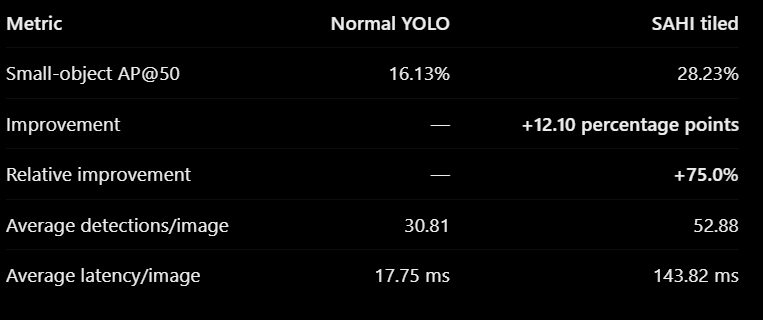

In [24]:

from google.colab import files
import os
import zipfile

results_folder = "/content/P10_results"
zip_path = "/content/P10_results_backup.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for root, dirs, filenames in os.walk(results_folder):
        for filename in filenames:
            filepath = os.path.join(root, filename)
            z.write(filepath, os.path.relpath(filepath, results_folder))

files.download(zip_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>